[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_hamilt.ipynb)


# Hamiltonian mechanics

Hamiltonian formulation of mechanics is equivalent form of EoM of a mechanical system. It is very useful for developing perturbation methods and understanding wide range of topics beyond mechanics  including optics, statistical physics, quantum mechanics etc.

## Legendre transform and Hamiltonian

The Legendre transform replaces a function’s argument with its derivative. For a convex function $f\left(x\right)$, define

$$
F\left(p,x\right)=p x-f\left(x\right)\tag{1}
$$

it is simply the difference between the line $p x$ and $f\left(x\right)$

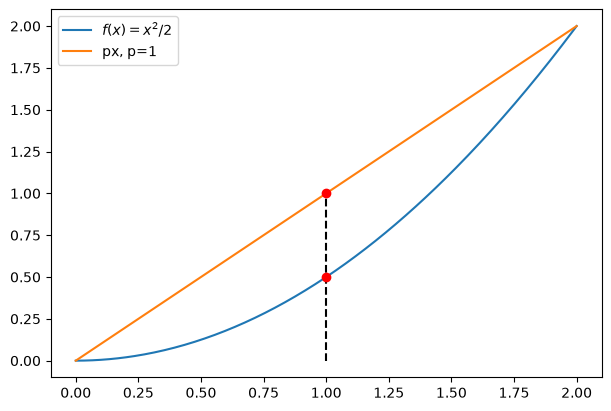

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display


def animate_parameter(draw,minimum,maximum,value,step,label):
    draw(value)
    slider=widgets.FloatSlider(value=value,min=minimum,max=maximum,step=step,
                               description=label,continuous_update=False)
    play=widgets.Play(value=0,min=0,max=int(round((maximum-minimum)/step)),step=1,interval=120,repeat=False)
    def advance(change):
        slider.value=min(maximum,minimum+change['new']*step)
    play.observe(advance,names='value')
    view=widgets.interactive_output(lambda parameter: draw(parameter),{'parameter':slider})
    display(widgets.VBox([widgets.HBox([play,slider]),view]))
    return slider,play,view

x=np.linspace(0,2,300)
fig,ax=plt.subplots(figsize=(6,4),layout='constrained'); ax.plot(x,x*x/2,label=r'$f(x)=x^2/2$'); ax.plot(x,x,label='px, p=1')
ax.plot([1,1],[0,1],'k--'); ax.plot([1,1],[1,.5],'ro'); ax.legend(); plt.show()

For a differentiable strictly convex function, the stationary point, when it exists, is the unique maximum of $F\left(p,x\right)$:

$$
\frac{\partial F}{\partial  x}=0\Rightarrow p=f'\left(x\right)\Rightarrow x\left(p\right)\tag{2}
$$

therefore one can define the function

$$
g\left(p\right)=F\left(p,x\left(p\right)\right)\tag{3}
$$

Under the usual convexity assumptions, applying the Legendre transform twice recovers the original function:

$$
G\left(x,p\right)=x p-g\left(p\right)\Rightarrow \frac{\partial G}{\partial  p}=0\Rightarrow x=g'\left(p\right)\Rightarrow p\left(x\right)\\ G\left(x,p\left(x\right)\right)=x p\left(x\right)-g\left(p\left(x\right)\right)=x p\left(x\right)-F\left(p,x\left(p\right)\right)=f\left(x\right)\tag{4}
$$

Besides

$$
x p \le g\left(p\right)+f\left(x\right), \forall  x,p\,\,\, {\rm where\, functions\, defined}
$$

For $f\left(x\right)=ax+b$, the finite Legendre transform is defined only at $p=a$, where $g\left(a\right)=-b$ (and is $+\infty$ elsewhere in the extended-real convention). Thus lines correspond to points and vice versa.



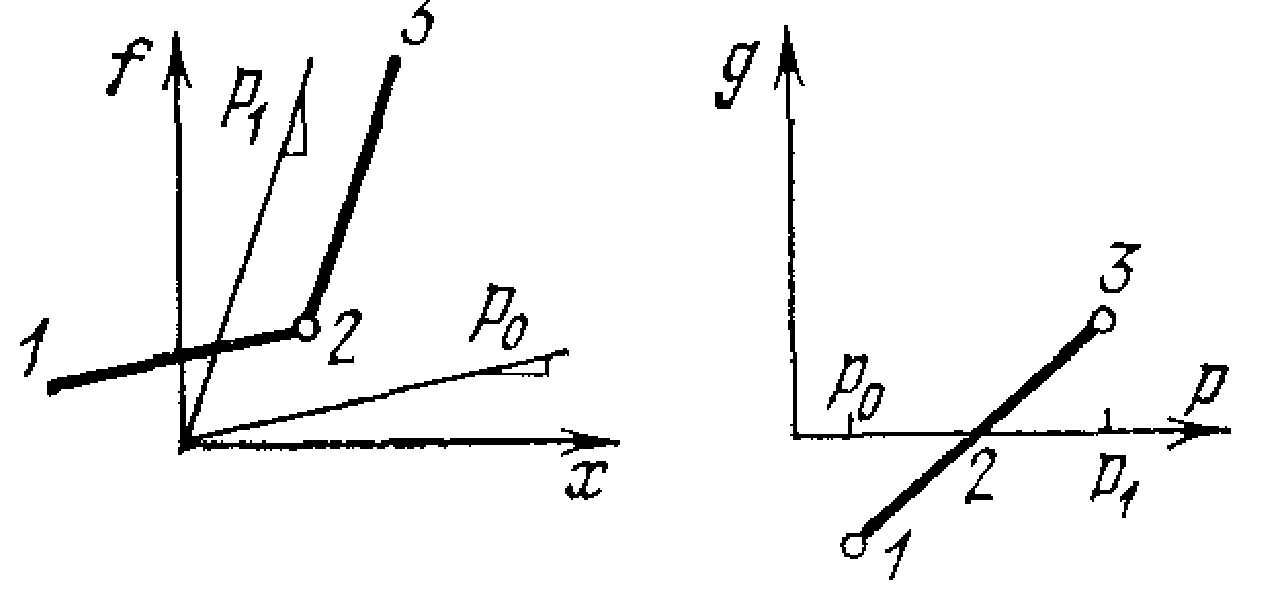



 Let’s find Legendre transform for $f\left(x\right)={x}^{2}$/2

$$
F\left(p,x\right)=p x -\frac{{x}^{2}}{2}\Rightarrow \frac{\partial F}{\partial  x}=0\Rightarrow p=x\Rightarrow g\left(p\right)=\frac{{p}^{2}}{2}\tag{5}
$$

another example

$$
f\left(x\right)=\frac{{x}^{\alpha }}{\alpha }\Rightarrow F\left(p,x\right)=p x -\frac{{x}^{\alpha }}{\alpha }\Rightarrow \frac{\partial F}{\partial  x}=0\Rightarrow p={x}^{\alpha -1}\Rightarrow g\left(p\right)=\frac{{p}^{\beta }}{\beta }, \beta =\frac{\alpha }{\alpha -1}\tag{6}
$$

## Hamilton’s equations of motion

In [2]:
# All dependencies are imported above. No proprietary runtime or working-directory setup is needed.

In mechanics the Legendre transform of the Lagrange function over generalized velocities $\dot{q}$ gives the Hamiltonian function of momenta p:

$$
H\left(p,q,t\right)=p \dot{q} -L\left(\dot{q},q,t\right)\Rightarrow \frac{\partial H}{\partial  \dot{q}}=0\Rightarrow p=\frac{\partial L}{\partial \dot{q}}\tag{7}
$$

so that 

$$
dH\left(p,q,t\right)=\frac{\partial H}{\partial t}dt+\frac{\partial H}{\partial q}dq +\frac{\partial H}{\partial p}dp=d\left(p \dot{q} -L\left(\dot{q},q,t\right)\right)=\\ =\dot{q} dp+p d\dot{q} -\frac{\partial L}{\partial t}dt-\frac{\partial L}{\partial q}dq -\frac{\partial L}{\partial \dot{q} }d\dot{q}=\dot{q} dp-\frac{\partial L}{\partial t}dt-\dot{p}dq\tag{8}
$$

Here the notation is abbreviated as

$$
p\dot{q}\to {\sum }_{i}^{n}{p}_{i}{\dot{q}}^{i}\tag{9}
$$

Comparing the differentials on both sides gives Hamilton’s equations:

$$
\dot{q}=\frac{\partial H}{\partial p},\dot{p}=-\frac{\partial H}{\partial q}\tag{10}
$$

and

$$
{\left(\frac{\partial H}{\partial t}\right)}_{p,q}=-{\left(\frac{\partial L}{\partial t}\right)}_{\dot{q},q}\tag{11}
$$

If the Lagrange function depends on other parameters О» then analogously (prove by yourself!)

$$
{\left(\frac{\partial H}{\partial \lambda }\right)}_{p,q}=-{\left(\frac{\partial L}{\partial \lambda }\right)}_{\dot{q},q}\tag{12}
$$

Thus we have two equivalent forms of EoM: Lagrangian and Hamiltonian, provided that there is 1-1 correspondence between coordinates-momenta phase space and coordinates-velocities configurational space. This can be guaranteed if the Lagrange function is convex wrt generalized velocities $\dot{{q}_{i}}$ or, equivalently Hessian matrix

$$\frac{\partial p_j}{\partial\dot q^i}=\frac{\partial^2L}{\partial\dot q^i\partial\dot q^j},\qquad \det\left(\frac{\partial^2L}{\partial\dot q^i\partial\dot q^j}\right)\ne0.\tag{13}
$$

with ${\rm det\, Hessian}_{L} \ne 0$. Such Lagrange functions are called non-singular.

Due to relation between the Lagrange and Hamiltonian functions the  equations can be derived from variation of functional:

$$
S = {\int }_{{t}_{1}}^{{t}_{2}}L\left(t,q,\dot{q}\right)dt={\int }_{{t}_{1}}^{{t}_{2}}\left(p\dot{q}-H\right)dt={\int }_{{t}_{1}}^{{t}_{2}}\left(p dq-H dt\right)\tag{14}
$$

Under small variation of the trajectory:

$$
\delta S={\int }_{{t}_{1}}^{{t}_{2}}\left(\delta p dq-dp\delta q+d\left(p\delta q\right)\right)-{\int }_{{t}_{1}}^{{t}_{2}}\left(\frac{\partial H}{\partial q}\delta q+\frac{\partial H}{\partial p}\delta p\right)dt=\\ \left.p\delta q\right|_{{t}_{1}}^{{t}_{2}}-{\int }_{{t}_{1}}^{{t}_{2}}\left(\left(\frac{dp}{dt}+\frac{\partial H}{\partial q}\right)\delta q+\left(-\frac{dq}{dt}+\frac{\partial H}{\partial p}\right)\delta p\right)dt=0\tag{15}
$$

which gives EoM in Hamiltonian form. Also using the above Hamiltonian representation of an action S we can get other relations. Let’s consider action as function on the real trajectories ${S}_{{t}_{0},{q}_{0}}$(t,q) with fixed initial point then

$$
dS =p dq-H dt\Rightarrow p=\frac{\partial S}{\partial q}, \frac{\partial S}{\partial t}+H=0\tag{16}
$$

Therefore we get the equation for ${S}_{{t}_{0},{q}_{0}}(t,q)$

$$
\frac{\partial S}{\partial t}+H\left(\frac{\partial S}{\partial q},q,t\right)=0\tag{17}
$$

This is the __Hamilton–Jacobi__ equation, a first-order partial differential equation for the action. Its characteristic curves satisfy Hamilton’s first-order ordinary differential equations. For an isotropic kinetic energy, their spatial directions are normal to surfaces of constant reduced action.

## Optical–mechanical analogy

[Continue with the optical–mechanical analogy lecture](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_optmechanalog.ipynb).

## Addition: Jacobi’s theorem

A complete integral $S(t,q;\alpha)$ of the Hamilton–Jacobi equation, with $n$ essential parameters $\alpha_a$, determines the mechanical motion by Jacobi’s theorem. An arbitrary additive constant is not counted among these parameters.

$$S=c+S_0(t,q;\alpha_1,\ldots,\alpha_n).\tag{18}
$$

and if

$$\det\left(\frac{\partial^2S}{\partial q^i\partial\alpha_a}\right)\ne0.\tag{19}
$$

then the following is true:

$$
\mathbf{p}\mathbf{=}\frac{\partial S}{\partial \mathbf{q}} and \mathbf{\beta }\mathbf{=}\frac{\partial S}{\partial \mathbf{α}}-some constants\tag{20}
$$

and due to (20) we can write

$$
\mathbf{q}\left(t,\mathbf{α},\mathbf{\beta }\right), \mathbf{p}\left(t,\mathbf{α},\mathbf{\beta }\right)\tag{21}
$$

which are exactly solutions of (10).

### Proof:

We have

$$
0=\frac{d\beta }{dt}=\frac{{\partial }^{2}S}{\partial t\partial \mathbf{α}}+\frac{d\mathbf{q}}{dt}\frac{{\partial }^{2}S}{\partial \mathbf{q}\partial \mathbf{α}}
$$

differentiating (17) by α:

$$
\frac{{\partial }^{2}S}{\partial t\partial \mathbf{α}}+\frac{{\partial }^{2}S}{\partial \mathbf{q}\partial \mathbf{α}}\frac{\partial H}{\partial  \mathbf{p}}=0\Rightarrow \frac{d\mathbf{q}}{dt}=\frac{\partial H}{\partial  \mathbf{p}}\tag{22}
$$

By the same virtue we get (by yourself):

$$
\frac{d\mathbf{p}}{dt}=-\frac{\partial H}{\partial \mathbf{q}}
$$

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)